In [1]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity
from transformers import pipeline

import gensim
from gensim.corpora import Dictionary
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

sns.set_theme(style="whitegrid")

In [3]:
np.random.seed(42)

# Question 3

### Question 3.1

In [5]:
filenames = ["research_1", "research_2", "research_3", "research_4", "research_5"]
documents = {}

for filename in filenames:
    with open("Datasets/research_corpus/" + filename + ".txt", "r", encoding="utf-8") as file:
        documents[filename] = file.read()

In [7]:
df = pd.DataFrame({
    "Filename": list(documents.keys()),
    "Content": list(documents.values())
})

### Question 3.2

In [9]:
def denoise_text(text):
    #Repairs split words across lines
    text = re.sub(r'-\s*\r?\n\s*', '', text)

    # Remove keywords section
    text = re.sub(r'\bKeywords:\s*.*?(?=\bIntroduction\b)', '', text, flags=re.IGNORECASE | re.DOTALL)

    # Removes page references
    text = re.sub(r'\(p{1,2}\.\s*\d+\)', '', text, flags=re.IGNORECASE)
    
    #Removes standalone page numbers
    text = re.sub(r'(?m)^\s*\d{1,4}\s*$', '', text)
    
    #Removes corrupted control characters
    text = text.replace('\x01', '')

    #Remove journal running headers and page numbers
    text = re.sub(r'DEVELOPMENTAL RESEARCH\s*[•·]?\s*\d+', '', text, flags=re.IGNORECASE)

    #Remove superscript footnote markers after sentence punctuation
    text = re.sub(r'(?<=[.!?])\s*\d{1,2}(?=\s+[A-Z])', '', text)
    
    #Fix spaces before punctuation
    text = re.sub(r'\s+([.,;:!?])', r'\1', text)

    # Remove corrupted arrow symbols
    text = text.replace('\u21d2', '')

    # Remove incomplete page references
    text = re.sub(r'\(p{1,2}\.\s*\d+\)', '', text, flags=re.IGNORECASE)

    #Remove references
    text = re.sub(r'\([^)]*\b(?:19|20)\d{2}[a-z]?\b[^)]*\)', '', text)

    # Remove spaces before punctuation
    text = re.sub(r'\s+([.,;:!?])', r'\1', text)
    
    # Removes table captions
    text = re.sub(r'\bTABLE\s+\d+[A-Z]?\.*', '', text, flags=re.IGNORECASE)
    
    #Removes unnecessary white space
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [11]:
df["Clean Content"] = df["Content"].apply(denoise_text)

In [13]:
df.head()

,Filename,Content,Clean Content
0,research_1,The purposes of this article are to position m...,The purposes of this article are to position m...
1,research_2,"Now I see it, now I don’t:\nresearcher’s posit...","Now I see it, now I don’t: researcher’s positi..."
2,research_3,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...,DEVELOPMENTAL RESEARCH: STUDIES OF INSTRUCTION...
3,research_4,Abstract\nCronbach’s alpha is a statistic comm...,Abstract Cronbach’s alpha is a statistic commo...
4,research_5,Denzin’s Paradigm Shift: Revisiting Triangulat...,Denzin’s Paradigm Shift: Revisiting Triangulat...


For the first article, the text repeats itself once so i must be removed

In [15]:
def remove_duplicates(text):
    sentences = sent_tokenize(text)

    unique_sentences = []
    seen = set()

    for sentence in sentences:
        key = sentence.strip().lower()

        if key not in seen:
            unique_sentences.append(sentence.strip())
            seen.add(key)

    return " ".join(unique_sentences)

In [17]:
df.loc[df["Filename"] == "research_1", "Clean Content"] = (
    df.loc[df["Filename"] == "research_1", "Clean Content"]
    .apply(remove_duplicates)
)


### Question 3.3

In [19]:
nltk.download('punkt_tab')
stop_words = set(stopwords.words("english"))

def sentences_of(text):
    return sent_tokenize(text)

def content_words(sentence):
    return [w for w in re.findall(r"[a-z]+", sentence.lower()) if w not in stop_words and len(w) > 2]

def pick(sentences, scores, n):
    top = sorted(np.argsort(scores)[::-1][:n])
    return " ".join(sentences[i] for i in top)

[nltk_data] Downloading package punkt_tab to C:\Users\Jean
[nltk_data]     Kotze\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [21]:
research_1_text = df.loc[df["Filename"] == "research_1", "Clean Content"].iloc[0]
research_1_sents = sentences_of(research_1_text)

In [23]:
def textrank(sentences):
    X = TfidfVectorizer(stop_words='english').fit_transform(sentences)
    sim = cosine_similarity(X)
    np.fill_diagonal(sim, 0)
    G = nx.from_numpy_array(sim)
    pr = nx.pagerank(G, weight="weight")
    return np.array([pr[i] for i in range(len(sentences))]), G

def textrank_summary(text, n=3):
    sents = sentences_of(text)
    scores, _ = textrank(sents)
    return pick(sents, scores, n)

tr_scores, G = textrank(research_1_sents)
print(textrank_summary(research_1_text, 3))

The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful. Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research.


In [25]:
top_scores = np.argsort(tr_scores)[::-1][:40]
G_top40 = G.subgraph(top_scores)
pos = nx.spring_layout(G_top40, seed=3, weight="weight")
widths = [G[u][v]["weight"] * 6 for u, v in G.edges()]
top3 = set(np.argsort(tr_scores)[::-1][:3])
print(top3)

{0, 30, 22}


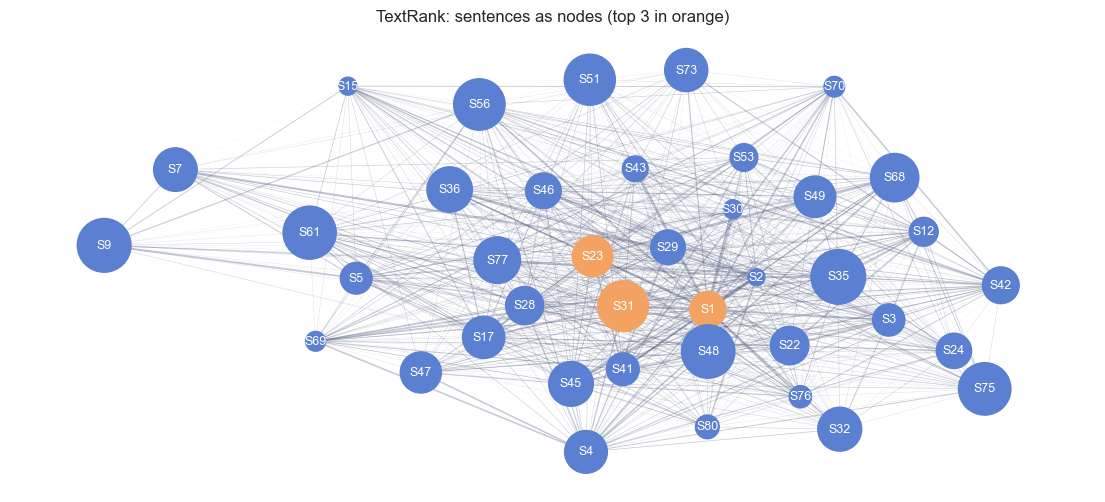

In [27]:
plt.figure(figsize=(14, 6))
nx.draw_networkx_edges(G_top40, pos, width=widths, alpha=0.35, edge_color="#5B6584")
nx.draw_networkx_nodes(G_top40, pos, node_size=top_scores / top_scores.max() * 1400 + 150,
                       node_color=["#F4A261" if i in top3 else "#5B7FD1" for i in G_top40.nodes()])
nx.draw_networkx_labels(G_top40, pos, labels={i: f"S{i+1}" for i in G_top40.nodes()}, font_color="white", font_size=9)
plt.title("TextRank: sentences as nodes (top 3 in orange)"); plt.axis("off"); plt.show()

### Question 3.4

For the aggregate summary, first we'll get the top 15 sentences of each with textrank then summarize each through a transformer, then summarize the summaries combined.

In [29]:
article_names = ["research_2", "research_3", "research_4", "research_5"]

textrank_summaries = {}

textrank_graphs = {}

for name in article_names:

    text = df.loc[df["Filename"] == name, "Clean Content"].iloc[0]
    sentences = sent_tokenize(text)

    scores, article_graph = textrank(sentences)

    summary = pick(sentences, scores, n=15)

    textrank_summaries[name] = summary
    textrank_graphs[name] = article_graph

    print(f"\n--- {name} ---")
    print(summary)


--- research_2 ---
Now I see it, now I don’t: researcher’s position and reflexivity in qualitative research Roni Berger Adelphi University, USA Abstract This article addresses potential effects on reflexivity of researcher’s social position (e.g. Because reflexivity is a major strategy for quality control in qualitative research, understanding how it may be impacted by the characteristics and experiences of the researcher is of paramount importance. Benefits and challenges to reflexivity under three types of researcher’s position are discussed and illustrated by means of case examples: (1) reflexivity when researcher shares the experience of study participants, (2) reflexivity when researcher moves from the position of an outsider to the position of an insider in the course of the study, and (3) reflexivity when researcher has no personal familiarity or experience with what is being studied. Keywords insider–outsider, reflexivity, researcher position, rigor, trustworthiness The main p

In [31]:
summariser = pipeline(
    "summarization",
    model="sshleifer/distilbart-cnn-12-6",
    framework="pt"
)

Device set to use cpu


In [33]:
individual_summaries = {}

for name, text in textrank_summaries.items():

    result = summariser(
        text,
        max_length=200,
        min_length=80,
        do_sample=False,
        truncation=True
    )

    individual_summaries[name] = result[0]["summary_text"]

    print(f"\n--- {name} ---")
    print(individual_summaries[name])


--- research_2 ---
 The main purpose of this article is to argue and illustrate that reflexivity in qualitative research is affected by whether the researcher is part of the researched and shares the participants’ experience . The relationship between reflexivity and the position of the researcher vis-à-vis the phenomenon under study has been only sparsely addressed . This article discusses issues relative to reflexivity under varying types of researcher’s personal experience with the world being studied .

--- research_3 ---
 In its simplest form, developmental research can be either the study of the process and impact of specific instructional design and development efforts; or a situation in which someone is performing instructional design, development, or studying the process at the same time . This type of research typically falls within the scope of traditional evaluation research . The distinctions between “doing” and “studying’s” research provide further clarification of devel

In [35]:
combined_summaries = "\n\n".join([
    f"Research 2: {individual_summaries['research_2']}",
    f"Research 3: {individual_summaries['research_3']}",
    f"Research 4: {individual_summaries['research_4']}",
    f"Research 5: {individual_summaries['research_5']}"
])

print(combined_summaries)

Research 2:  The main purpose of this article is to argue and illustrate that reflexivity in qualitative research is affected by whether the researcher is part of the researched and shares the participants’ experience . The relationship between reflexivity and the position of the researcher vis-à-vis the phenomenon under study has been only sparsely addressed . This article discusses issues relative to reflexivity under varying types of researcher’s personal experience with the world being studied .

Research 3:  In its simplest form, developmental research can be either the study of the process and impact of specific instructional design and development efforts; or a situation in which someone is performing instructional design, development, or studying the process at the same time . This type of research typically falls within the scope of traditional evaluation research . The distinctions between “doing” and “studying’s” research provide further clarification of developmental resear

In [37]:
aggregate_result = summariser(
    combined_summaries,
    max_length=250,
    min_length=120,
    do_sample=False,
    truncation=True
)

final_summary = aggregate_result[0]["summary_text"]

print(final_summary)

 The relationship between reflexivity and the position of the researcher vis-à-vis the phenomenon under study has been only sparsely addressed . Cronbach’s alpha is regularly adopted in studies in science education: it was referred to in 69 different papers published in 4 leading science education journals in a single year . Triangulation (multiple sources of data) can enhance the reliability of the study results and enable one to saturate the data . In qualitative research, triangulation adds depth to the data that is collected . The distinctions between “doing” and “studying’” research provide further clarification of developmental research activities .


## Question 4

### Question 4.1

In [49]:
documents = df["Clean Content"].dropna().tolist()

In [51]:
stop_words = set(stopwords.words("english"))

def preprocess_lda(text):
    #Remove punctuation, special characters, numbers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    #Lowercase
    text = text.lower()

    #Tokenize
    tokens = word_tokenize(text)

    #Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]

    text = " ".join(tokens)

    return tokens

documents = df["Clean Content"].dropna().apply(preprocess_lda).tolist()

In [53]:
dictionary = Dictionary(documents)
dictionary.filter_extremes(no_below=1, no_above=0.5)
bow_corpus = [dictionary.doc2bow(text) for text in documents]

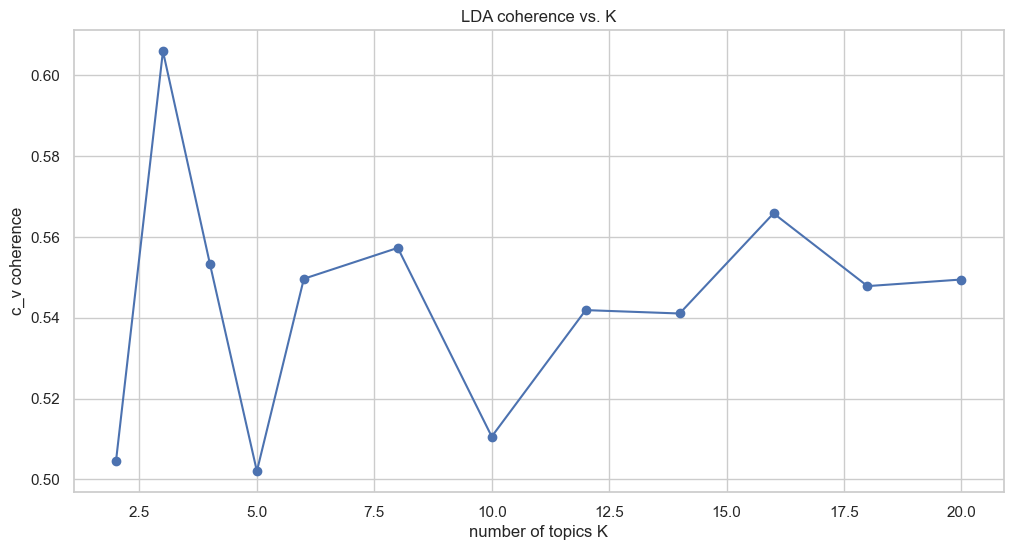

{2: 0.504, 3: 0.606, 4: 0.553, 5: 0.502, 6: 0.55, 8: 0.557, 10: 0.511, 12: 0.542, 14: 0.541, 16: 0.566, 18: 0.548, 20: 0.549}


In [55]:
scores = {}
for k in [2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20]:
    m = LdaModel(bow_corpus, num_topics=k, id2word=dictionary, passes=10, alpha='auto', eta='auto', random_state=42)
    scores[k] = CoherenceModel(model=m, texts=documents, dictionary=dictionary, coherence='c_v').get_coherence()

plt.figure(figsize=(12,6)); plt.plot(list(scores), list(scores.values()), marker="o")
plt.xlabel("number of topics K"); plt.ylabel("c_v coherence"); plt.title("LDA coherence vs. K"); plt.show()
print({k: round(float(v),3) for k,v in scores.items()})

Best coherence score: 0.606 for k = 3 topics.

In [59]:
ldamodel = LdaModel(bow_corpus, num_topics=3, id2word=dictionary, passes=20, alpha='auto', eta='auto', random_state=42)

# Get the topics
topics = ldamodel.show_topics(num_topics=3, num_words=10, log=False, formatted=False)

# Print the topics
for topic_id, topic in topics:
    print("Topic: {}".format(topic_id))
    print("Words: {}".format([word for word, _ in topic]))

Topic: 0
Words: ['alpha', 'cronbach', 'instrument', 'reliability', 'items', 'education', 'reflexivity', 'authors', 'mixed', 'scales']
Topic: 1
Words: ['denzin', 'mixed', 'fusch', 'bias', 'sources', 'designs', 'personal', 'rich', 'ness', 'blended']
Topic: 2
Words: ['developmental', 'instructional', 'type', 'models', 'product', 'term', 'processes', 'technology', 'production', 'systems']


In [61]:
pd.DataFrame({f"Topic {tid}": [f"{w} ({p:.6f})" for w, p in words[:6]] for tid, words in topics})

,Topic 0,Topic 1,Topic 2
0,alpha (0.027414),denzin (0.016706),developmental (0.023989)
1,cronbach (0.015031),mixed (0.011413),instructional (0.021823)
2,instrument (0.013632),fusch (0.010810),type (0.009922)
3,reliability (0.011060),bias (0.009644),models (0.007756)
4,items (0.008256),sources (0.007872),product (0.007223)
5,education (0.007789),designs (0.006691),term (0.005593)


In [63]:
doc_topics = np.array([[p for _, p in ldamodel.get_document_topics(b, minimum_probability=0)] for b in bow_corpus])
dt = pd.DataFrame(doc_topics, columns=[f"Topic {i}" for i in range(3)])
dt["Filename"] = df["Filename"].values

In [65]:
dt.head()

,Topic 0,Topic 1,Topic 2,Filename
0,0.997982,0.001050,0.000968,research_1
1,0.997876,0.001102,0.001023,research_2
2,0.000624,0.000578,0.998798,research_3
3,0.999366,0.000312,0.000322,research_4
4,0.000761,0.998554,0.000685,research_5


In [67]:
for topic_id, words in ldamodel.show_topics(
    num_topics=3,
    num_words=10,
    formatted=False
):
    print(f"\nTopic {topic_id}:")
    print(", ".join([word for word, probability in words]))


Topic 0:
alpha, cronbach, instrument, reliability, items, education, reflexivity, authors, mixed, scales

Topic 1:
denzin, mixed, fusch, bias, sources, designs, personal, rich, ness, blended

Topic 2:
developmental, instructional, type, models, product, term, processes, technology, production, systems


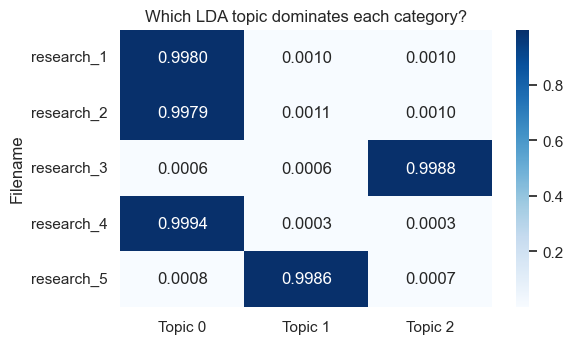

In [69]:
plt.figure(figsize=(6,3.6))
sns.heatmap(dt.groupby("Filename").mean(), annot=True, fmt=".4f", cmap="Blues")
plt.title("Which LDA topic dominates each category?"); 
plt.show()

### Question 4.2

In [71]:
vis = gensimvis.prepare(
    ldamodel,
    bow_corpus,
    dictionary
)

In [73]:
print(vis.topic_coordinates)

              x         y  topics  cluster       Freq
topic                                                
0      0.123179 -0.070997       1        1  63.881629
2     -0.133136 -0.056176       2        1  19.448658
1      0.009957  0.127173       3        1  16.669713


In [75]:
pyLDAvis.display(vis)